[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/04_objectives_and_transfer.ipynb)

# 04 · Pretraining Objectives and Transfer: What the Model Is Asked to Predict, and What It Learns From It

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Counting and embeddings | Count n-grams; learn word vectors | A first language model; similar words get similar vectors | Fixed window; one vector per word |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| **04** | **Objectives and transfer** | **Causal, masked and span-corruption pretraining** | **Representations that transfer with few labels** | **No objective wins everything; optimisation untested** |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

Notebook 03 built the transformer and trained it to predict the next token. That is one choice of **pretraining
objective**, and for several years it was not the dominant one. BERT ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)) hid some of the tokens and
asked the model to fill them in, reading both sides. T5 ([Raffel et al., 2019](https://arxiv.org/abs/1910.10683)) and BART ([Lewis et al., 2019](https://arxiv.org/abs/1910.13461)) removed whole spans
and trained an encoder-decoder to write them back. ELECTRA ([Clark et al., 2020](https://arxiv.org/abs/2003.10555)) replaced tokens with plausible fakes and
asked which ones were fake.

This notebook pretrains **the same small transformer** with these objectives on the same documents and asks four
questions of each:

1. How quickly do useful representations appear during pretraining?
2. How well do they transfer to a labelled task with very few labels?
3. Can the model fill in a blank?
4. Can the model generate a document?

Then it takes the masked objective apart, one design choice at a time: how much to hide ([Wettig et al., 2022](https://arxiv.org/abs/2202.08005)), whether to
hide the same tokens every time ([Liu et al., 2019](https://arxiv.org/abs/1907.11692)), whether to hide spans ([Joshi et al., 2019](https://arxiv.org/abs/1907.10529)), and how the encoder knows
where tokens are.

## Learning objectives

1. State each objective exactly: what the model sees, what it predicts, and which positions it may read.
2. Measure representation quality with linear probes and few-label fine-tuning, and track it during pretraining.
3. Explain masking rate, dynamic masking, span masking and replaced-token detection, and measure each at small scale.
4. Say what an encoder, an encoder-decoder and a decoder can and cannot do, and why decoders became the default.

**Runtime:** about 24 minutes on a laptop CPU (twelve small models; the five main ones are trained for 3,000 steps
and measured every 500 steps).

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from prelib import world as W, classic as C, transformer as T, objectives as O, viz, metrics, set_seed
viz.style()
torch.set_num_threads(min(4, torch.get_num_threads()))
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
train, test, probe_docs = W.corpus("train"), W.corpus("test"), W.corpus("probe")

# One architecture for every model in this notebook: 2 layers, 64 dimensions, pre-norm, and a learned relative
# position bias (section 6 explains that choice). Only the objective, and the attention mask it needs, change.
BASE = dict(pos="relative", norm="pre", norm_type="rms", ffn="swiglu")
S15, S100, T15, FILL = "style, 15 labels", "style, 100 labels", "topic, 15 labels", "fill-in accuracy, words"
HIDDEN = np.random.default_rng(5).random(test["tokens"].shape) < 0.15; HIDDEN[:, 0] = False     # one fixed fill-in test for everyone
models, hist, secs = {}, {}, {}

def measure(model, fill_in=False):
    # the downstream measurements: linear probes on mean-pooled states, and (for encoders) a fill-in test
    feats = model.features(probe_docs["tokens"])
    s, t = O.probe_curve(feats, "style", (15, 100)), O.probe_curve(feats, "topic", (15,))
    out = {S15: s[15], S100: s[100], T15: t[15]}
    if fill_in:
        lp = O.cloze(model, test["tokens"], HIDDEN)
        out[FILL] = float((lp.argmax(-1) == test["tokens"])[HIDDEN & (test["kind"] == W.K_FILL)].mean())
    return out

def pretrain(name, objective, steps=3000, seed=0, arch=None, **kw):
    # objective: "causal", "masked", "span corruption" or "replaced-token detection"; measured every 500 steps
    set_seed(seed); arch = arch or BASE; track = []
    def every_500(step, model):
        if (step + 1) % 500 == 0:
            track.append({"step": step + 1, **measure(model, fill_in=objective == "masked")}); model.train()
    t0 = time.time()
    if objective == "causal":
        m = T.Transformer(**arch); C.train_lm(m, train["tokens"], steps=steps, seed=seed, callback=every_500)
    elif objective == "masked":
        m = T.Transformer(causal=False, **arch); O.train_mlm(m, train["tokens"], steps=steps, seed=seed, callback=every_500, **kw)
    elif objective == "span corruption":
        m = O.Seq2Seq(n_dec=1); O.train_span(m, train["tokens"], steps=steps, seed=seed, callback=every_500, **kw)
    else:
        m = O.Electra(**arch); O.train_electra(m, train["tokens"], steps=steps, seed=seed, callback=every_500, **kw)
    models[name], hist[name], secs[name] = m, pd.DataFrame(track).set_index("step"), time.time() - t0
    last = hist[name].iloc[-1]
    print(f"{name:38s} style probe with 15 / 100 labels: {last[S15]:.2f} / {last[S100]:.2f}   topic: {last[T15]:.2f}   ({secs[name]:.0f}s)")

## 1. Three objectives, one document

All three objectives are "hide something, predict it". They differ in what is hidden and in which positions the
model may read while predicting.

| Objective | The model sees | It predicts | It may read | Architecture |
|---|---|---|---|---|
| **Causal** (GPT) | the tokens so far | the next token, at every position | earlier positions only | decoder |
| **Masked** (BERT) | the document with about 15% of tokens hidden | the hidden tokens | the whole document | encoder |
| **Span corruption** (T5) | the document with spans replaced by markers | the missing spans, written out one token at a time | encoder: everything; decoder: its own earlier output and the encoder | encoder-decoder |

BERT's corruption has one more detail. If the model only ever saw `<mask>` at the positions it must predict, it would
learn nothing about positions that hold ordinary tokens, and `<mask>` never appears in downstream use. So of the
chosen positions 80% become `<mask>`, 10% become a random token and 10% are left as they are, and the model must
predict the original in all three cases.

The figure shows the same document under each objective: the top row of each pair is what the model reads, the bottom
row is what it is scored on.

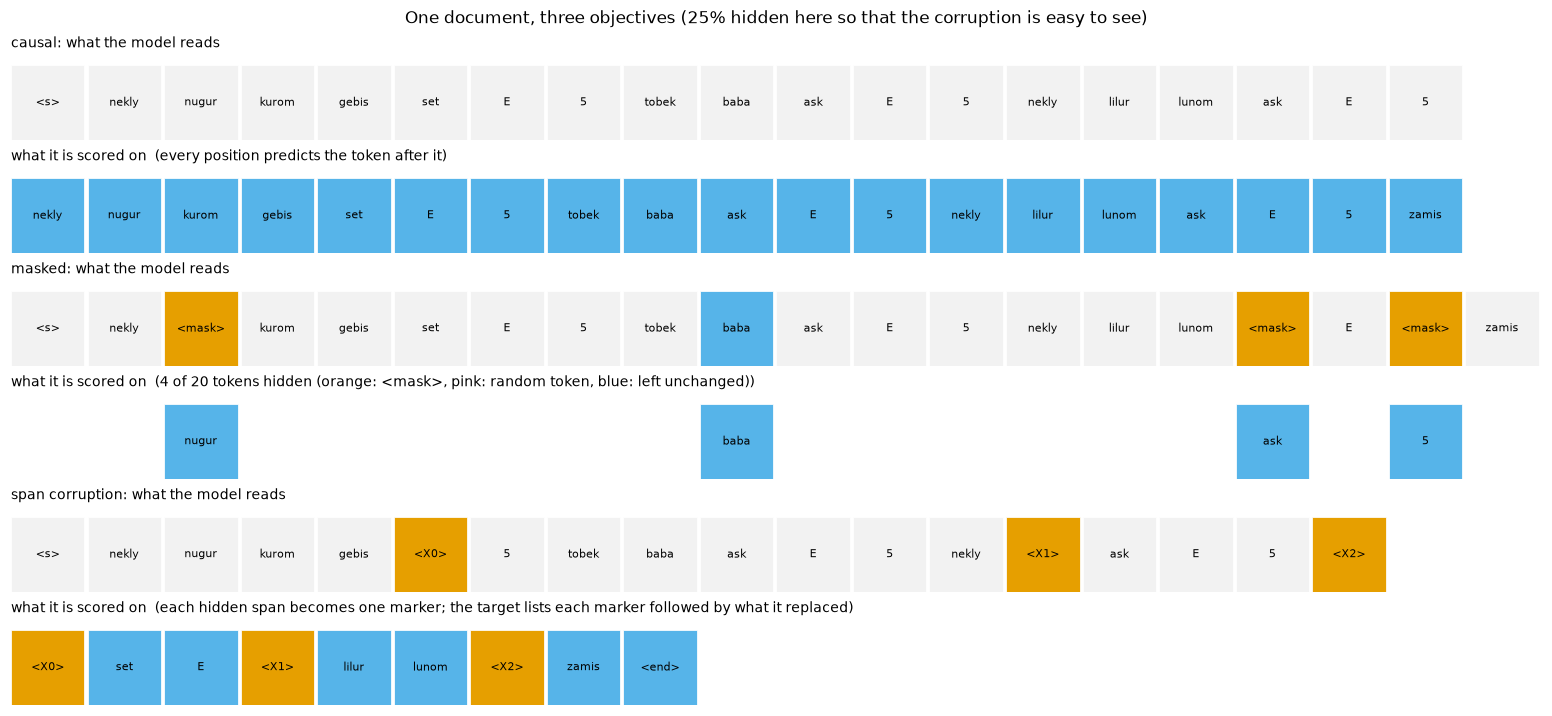

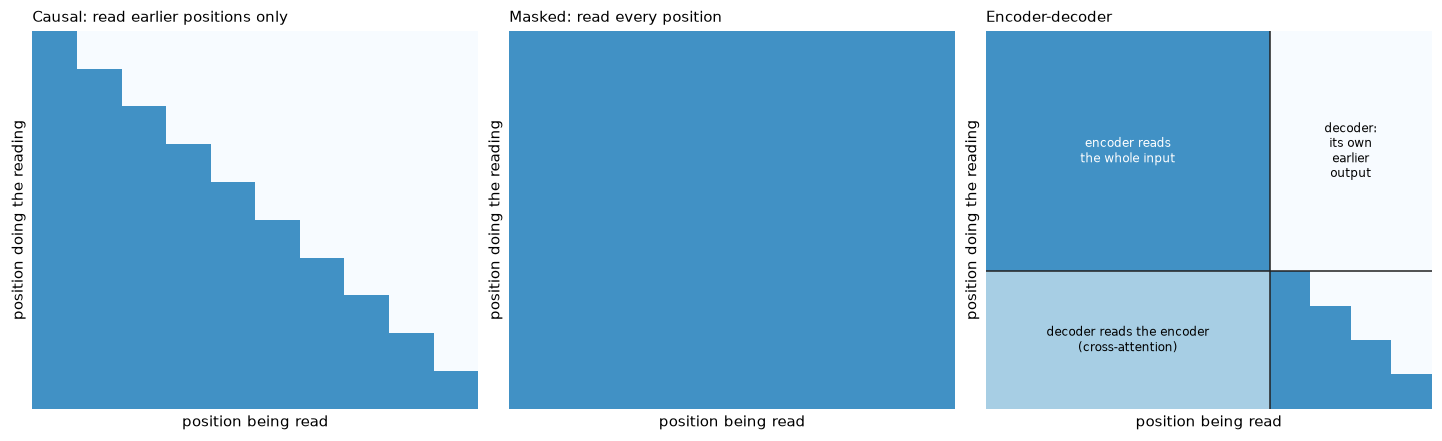

In [2]:
name_of = lambda t: W.WORDS[t] if t < W.VOCAB else f"<X{t - O.SENT0}>"
PLAIN = "#F2F2F2"
def draw_objective(ax_in, ax_out, objective, rate=0.15, document=3, length=20, seed=1):
    doc = test["tokens"][document][:length][None]; rng = np.random.default_rng(seed)
    if objective == "causal":
        seen, c_in = [name_of(t) for t in doc[0][:-1]], [PLAIN] * (length - 1)
        want, c_out = [name_of(t) for t in doc[0][1:]], [viz.SKY] * (length - 1)
        note = "every position predicts the token after it"
    elif objective == "masked":
        x, hidden = O.corrupt(doc, rate, rng)
        seen = [name_of(t) for t in x[0]]
        c_in = [viz.ORANGE if x[0, i] == W.MASK else viz.PINK if hidden[0, i] and x[0, i] != doc[0, i] else viz.SKY if hidden[0, i] else PLAIN for i in range(length)]
        want = [name_of(doc[0, i]) if hidden[0, i] else "" for i in range(length)]; c_out = [viz.SKY if h else "#FFFFFF" for h in hidden[0]]
        note = f"{hidden.sum()} of {length} tokens hidden (orange: <mask>, pink: random token, blue: left unchanged)"
    else:
        inp, dec_in, dec_out = O.span_corrupt(doc, rate, 3.0, rng)
        seen = [name_of(t) for t in inp[0] if t != W.PAD]; c_in = [viz.ORANGE if s.startswith("<X") else PLAIN for s in seen]
        want = ["<end>" if t == W.BOS else name_of(t) for t in dec_out[0] if t != W.PAD]; c_out = [viz.ORANGE if s.startswith("<X") else viz.SKY for s in want]
        note = "each hidden span becomes one marker; the target lists each marker followed by what it replaced"
    viz.token_strip(ax_in, seen, colors=c_in, wrap=length, fontsize=7); viz.token_strip(ax_out, want, colors=c_out, wrap=length, fontsize=7)
    ax_in.set_title(f"{objective}: what the model reads", fontsize=9, loc="left"); ax_out.set_title("what it is scored on  (" + note + ")", fontsize=9, loc="left")

fig, axes = plt.subplots(6, 1, figsize=(14, 6.4))
for k, objective in enumerate(["causal", "masked", "span corruption"]):
    draw_objective(axes[2 * k], axes[2 * k + 1], objective, rate=0.25 if objective != "causal" else 0)
fig.suptitle("One document, three objectives (25% hidden here so that the corruption is easy to see)")
plt.show()

n = 10
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
viz.heat(axes[0], np.tril(np.ones((n, n))), cmap="Blues", vmin=0, vmax=1.6); axes[0].set_title("Causal: read earlier positions only")
viz.heat(axes[1], np.ones((n, n)), cmap="Blues", vmin=0, vmax=1.6); axes[1].set_title("Masked: read every position")
ne, nd = 7, 4
M = np.zeros((ne + nd, ne + nd)); M[:ne, :ne] = 1; M[ne:, :ne] = 0.55; M[ne:, ne:] = np.tril(np.ones((nd, nd)))
viz.heat(axes[2], M, cmap="Blues", vmin=0, vmax=1.6); axes[2].axhline(ne - 0.5, color=viz.BLACK, lw=1); axes[2].axvline(ne - 0.5, color=viz.BLACK, lw=1)
axes[2].set_title("Encoder-decoder")
axes[2].text(ne / 2 - 0.5, ne / 2 - 0.5, "encoder reads\nthe whole input", ha="center", va="center", fontsize=8, color="white")
axes[2].text(ne / 2 - 0.5, ne + nd / 2 - 0.5, "decoder reads the encoder\n(cross-attention)", ha="center", va="center", fontsize=8)
axes[2].text(ne + nd / 2 - 0.5, ne / 2 - 0.5, "decoder:\nits own\nearlier\noutput", ha="center", va="center", fontsize=8)
for ax in axes:
    ax.set_xlabel("position being read"); ax.set_ylabel("position doing the reading"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

### Try it: change the objective and how much is hidden

Static preview at the default settings {'objective': 'masked', 'percent_hidden': 15, 'document': 3}. Run the notebook to get the controls.


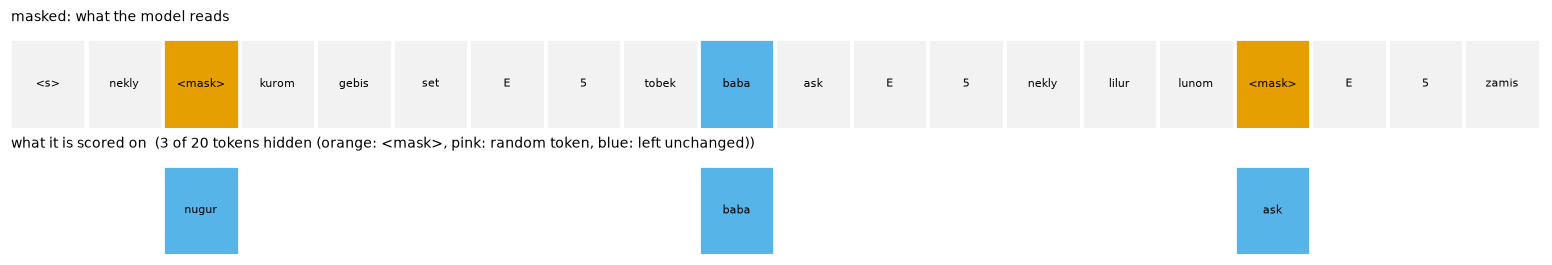

In [3]:
def objective_explorer(objective="masked", percent_hidden=15, document=3):
    fig, axes = plt.subplots(2, 1, figsize=(14, 2.3))
    draw_objective(axes[0], axes[1], objective, rate=percent_hidden / 100, document=document)
    plt.show()
viz.explore(objective_explorer, objective=["masked", "span corruption", "causal"], percent_hidden=(5, 80, 5, 15), document=(0, 50, 1, 3))

## 2. Pretraining three ways, and watching the representations form

We cannot compare these models by their training loss, because each loss measures something different. What we can
compare is what pre-training is for: **how useful the model's internal representations are for a task it was not
trained on.** As in notebook 02, the task is to recognise a document's hidden *style* (its word-order pattern) or its
hidden *topic* (its word preferences) from a handful of labelled documents. We average the model's final states over
the document and fit a linear classifier on top. This is a **linear probe**: the model itself is not changed.

Every 500 steps of pretraining we stop and measure three probes: style with 15 labelled documents, style with 100,
and topic with 15. Each number is an average over three random choices of which documents are labelled. Chance is
0.33 for style and 0.25 for topic.

The masked model is trained twice, with two random seeds, so that we can see how much of any difference is noise.
The encoder-decoder has a two-layer encoder like the others and a one-layer decoder on top.

In [4]:
pretrain("causal", "causal")
pretrain("masked", "masked", rate=0.15)
pretrain("masked, second seed", "masked", rate=0.15, seed=1)
pretrain("span corruption", "span corruption", rate=0.15)

causal                                 style probe with 15 / 100 labels: 0.40 / 0.78   topic: 1.00   (127s)
masked                                 style probe with 15 / 100 labels: 0.89 / 1.00   topic: 1.00   (122s)
masked, second seed                    style probe with 15 / 100 labels: 0.66 / 0.95   topic: 0.99   (130s)
span corruption                        style probe with 15 / 100 labels: 0.59 / 0.94   topic: 1.00   (175s)


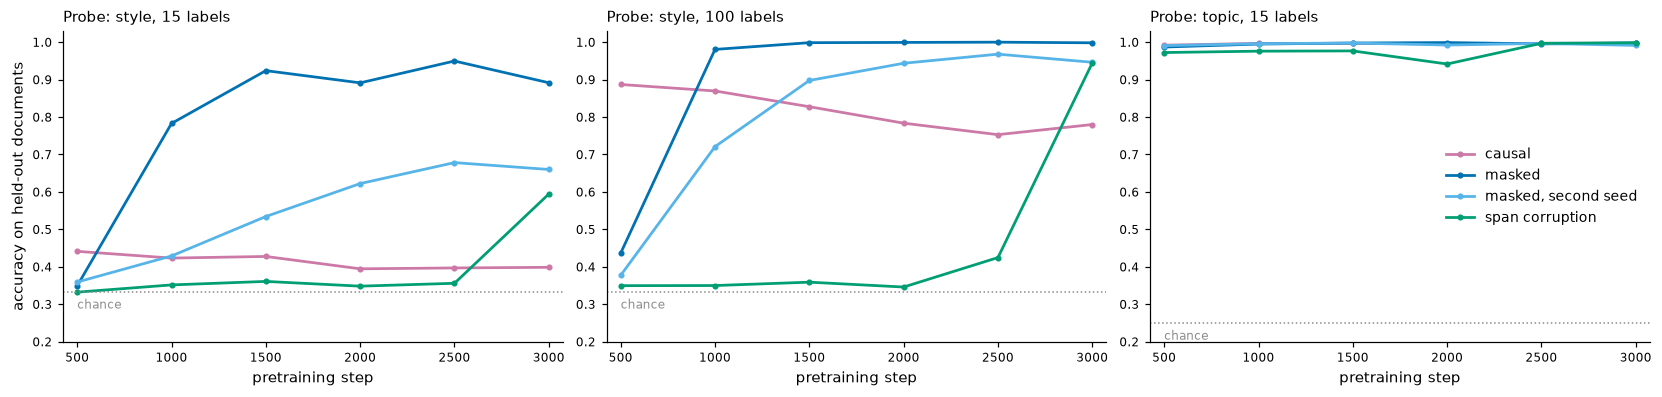

,"style, 15 labels","style, 100 labels","topic, 15 labels",parameters,seconds
causal,0.399,0.780,0.997,109081,127
masked,0.892,0.998,0.998,109337,122
"masked, second seed",0.660,0.946,0.991,109337,130
span corruption,0.594,0.944,0.998,182726,175


probe: style, 15 labels, every 500 steps


step,500,1000,1500,2000,2500,3000
causal,0.44,0.42,0.43,0.39,0.40,0.40
masked,0.35,0.78,0.92,0.89,0.95,0.89
"masked, second seed",0.36,0.43,0.53,0.62,0.68,0.66
span corruption,0.33,0.35,0.36,0.35,0.36,0.59


probe: style, 100 labels, every 500 steps


step,500,1000,1500,2000,2500,3000
causal,0.89,0.87,0.83,0.78,0.75,0.78
masked,0.44,0.98,1.00,1.00,1.00,1.00
"masked, second seed",0.38,0.72,0.90,0.94,0.97,0.95
span corruption,0.35,0.35,0.36,0.35,0.42,0.94


probe: topic, 15 labels, every 500 steps


step,500,1000,1500,2000,2500,3000
causal,0.99,1.00,1.00,1.00,1.0,1.00
masked,0.99,1.00,1.00,1.00,1.0,1.00
"masked, second seed",0.99,1.00,1.00,0.99,1.0,0.99
span corruption,0.97,0.98,0.98,0.94,1.0,1.00


In [5]:
MAIN = ["causal", "masked", "masked, second seed", "span corruption"]
COL = {"causal": viz.PINK, "masked": viz.BLUE, "masked, second seed": viz.SKY, "span corruption": viz.GREEN}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, chance in zip(axes, [S15, S100, T15], [1 / 3, 1 / 3, 1 / 4]):
    for name in MAIN:
        ax.plot(hist[name].index, hist[name][col], "o-", ms=3, color=COL[name], label=name)
    ax.axhline(chance, color=viz.GREY, ls=":", lw=1); ax.text(500, chance - 0.045, "chance", fontsize=8, color=viz.GREY)
    ax.set_ylim(0.2, 1.03); ax.set_xlabel("pretraining step"); ax.set_title("Probe: " + col)
axes[0].set_ylabel("accuracy on held-out documents"); axes[2].legend(loc="center right")
plt.show()
summary = pd.DataFrame({name: {**hist[name].iloc[-1][[S15, S100, T15]], "parameters": sum(p.numel() for p in models[name].parameters()),
                               "seconds": round(secs[name])} for name in MAIN}).T.astype({"parameters": int, "seconds": int})
display(summary.round(3))
for col in (S15, S100, T15):
    print(f"probe: {col}, every 500 steps")
    display(pd.DataFrame({name: hist[name][col] for name in MAIN}).T.round(2))

**Reading the result.**

* *Topic is learned by everything, at once.* Every model is at 0.94 or above on the topic probe from the first
  measurement on. Topic is a matter of which words occur, and any objective that predicts words must model it.
* *Style separates the objectives.* Style is a matter of word order. With 15 labels the masked model reaches 0.89,
  the encoder-decoder 0.59 and the causal model 0.40. With 100 labels they reach 1.00, 0.94 and 0.78.
* *The two masked runs differ by a lot.* The second seed ends at 0.66 with 15 labels where the first ends at 0.89,
  and it gets there more slowly. This is the yardstick for the rest of the notebook: a difference of 0.2 on the
  15-label probe between two single runs is not evidence of anything.
* *The causal model's features do not get better with training.* Its 100-label probe is highest at the first
  measurement (0.89 at step 500) and drifts down to 0.78. It keeps getting better at its own task while its averaged
  states become a little less convenient for ours.
* *The encoder-decoder learns style late.* Its encoder is close to chance on style until step 2,500 and jumps to
  0.94 (100 labels) at step 3,000. It also has more parameters (183,000 against 109,000) and takes longer per step.

One caution before reading this as "masked beats causal". The causal model here uses the same position scheme as
the encoders so that only the objective differs. The scorecard at the end of this notebook lists the causal models of
notebook 03, which used other position schemes and were measured on the same 100-label probe: they score between
0.75 and 1.00. The size of the causal model's deficit depends on its architecture; its direction, and the result of
section 4, are the robust part.

## 3. What the representations hold

Three closer looks at the pretrained models.

* **How many labels does each need?** The probe again, from 15 to 1,000 labelled documents, with two baselines that
  involve no pretraining: counting words, and the states of a transformer with random weights.
* **What does a single position know?** Instead of averaging over the document, we take the state at one position and
  ask the same question. A causal model's state at position 2 has seen two tokens. A bidirectional model's state at
  position 2 has seen the whole document.
* **What do the features look like?** The first two principal components of the document features, coloured by style
  and by topic.

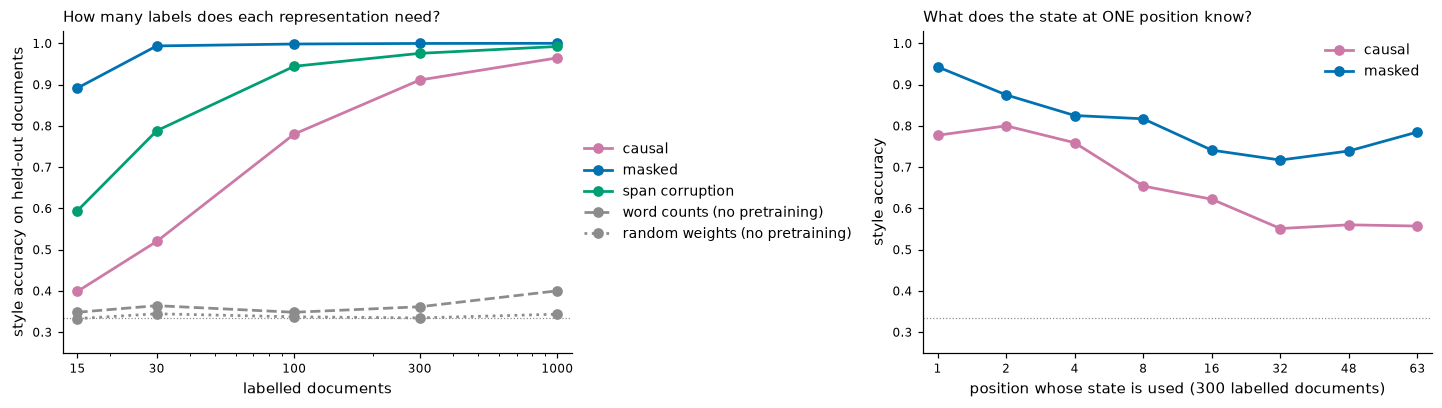

labelled documents,15,30,100,300,1000
causal,0.399,0.520,0.780,0.911,0.965
masked,0.892,0.994,0.998,1.000,1.000
span corruption,0.594,0.788,0.944,0.976,0.992
word counts (no pretraining),0.348,0.364,0.348,0.361,0.400
random weights (no pretraining),0.333,0.344,0.337,0.334,0.343


position,1,2,4,8,16,32,48,63
causal,0.777,0.800,0.759,0.654,0.622,0.551,0.560,0.557
masked,0.943,0.875,0.825,0.817,0.741,0.717,0.739,0.785


for comparison: guessing the style from the class of the first word alone is right 0.83 of the time


In [6]:
counts_fn = lambda tok: np.stack([np.bincount(t, minlength=W.VOCAB) for t in tok]).astype(float)
set_seed(0); untrained = T.Transformer(causal=False, **BASE)
LABELS = (15, 30, 100, 300, 1000)
THREE = ["causal", "masked", "span corruption"]
curves = {name: O.probe_curve(models[name].features, "style", LABELS) for name in THREE}
curves["word counts (no pretraining)"] = O.probe_curve(counts_fn, "style", LABELS)
curves["random weights (no pretraining)"] = O.probe_curve(untrained.features, "style", LABELS)
curves = pd.DataFrame(curves).T; curves.columns.name = "labelled documents"

POSITIONS = [1, 2, 4, 8, 16, 32, 48, 63]
def position_probe(model, n_labels=300):
    S = O.states(model, probe_docs["tokens"])
    return [O.probe_curve(S[:, t], "style", (n_labels,), draws=1)[n_labels] for t in POSITIONS]
by_position = pd.DataFrame({name: position_probe(models[name]) for name in ["causal", "masked"]}, index=pd.Index(POSITIONS, name="position")).T

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for name, col, ls in zip(curves.index, [viz.PINK, viz.BLUE, viz.GREEN, viz.GREY, viz.GREY], ["-", "-", "-", "--", ":"]):
    axes[0].plot(LABELS, curves.loc[name], "o", ls=ls, color=col, label=name)
axes[0].axhline(1 / 3, color=viz.GREY, ls=":", lw=0.8)
axes[0].set_xscale("log"); axes[0].set_xticks(LABELS); axes[0].set_xticklabels(LABELS); axes[0].tick_params(axis="x", which="minor", labelbottom=False)
axes[0].set_ylim(0.25, 1.03); axes[0].set_xlabel("labelled documents"); axes[0].set_ylabel("style accuracy on held-out documents")
axes[0].set_title("How many labels does each representation need?"); axes[0].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
for name, col in [("causal", viz.PINK), ("masked", viz.BLUE)]:
    axes[1].plot(range(len(POSITIONS)), by_position.loc[name], "o-", color=col, label=name)
axes[1].axhline(1 / 3, color=viz.GREY, ls=":", lw=0.8)
axes[1].set_xticks(range(len(POSITIONS))); axes[1].set_xticklabels(POSITIONS); axes[1].set_ylim(0.25, 1.03)
axes[1].set_xlabel("position whose state is used (300 labelled documents)"); axes[1].set_ylabel("style accuracy")
axes[1].set_title("What does the state at ONE position know?"); axes[1].legend()
plt.show()
display(curves.round(3)); display(by_position.round(3))
first = W.WORD_CLASS[probe_docs["tokens"][:, 1]]; ok = first >= 0
best_guess = sum(np.bincount(probe_docs["style"][ok & (first == c)], minlength=3).max() for c in range(6)) / ok.sum()
print(f"for comparison: guessing the style from the class of the first word alone is right {best_guess:.2f} of the time")

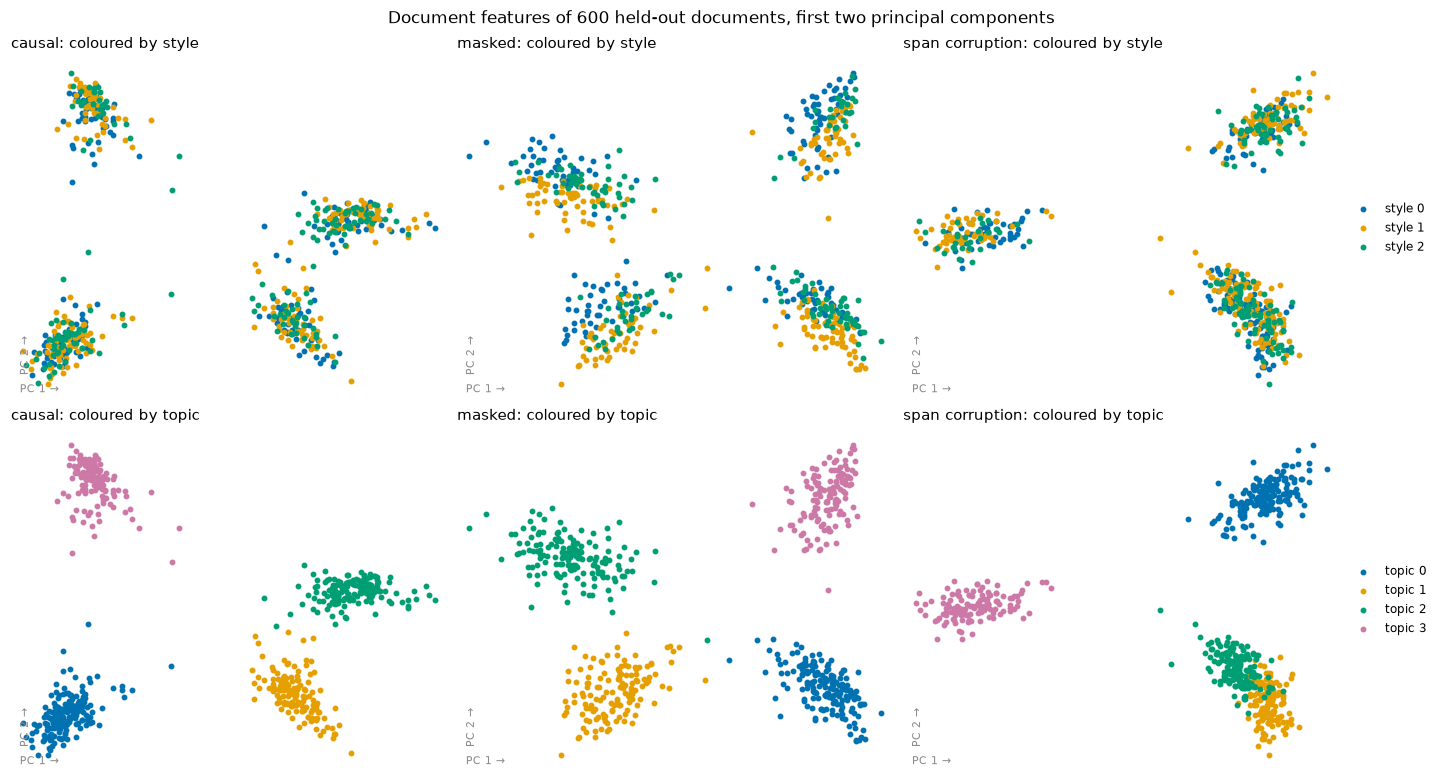

In [7]:
sub = np.arange(3000, 3600)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, name in enumerate(THREE):
    P = viz.pca2(models[name].features(probe_docs["tokens"][sub]))
    for i, (label, n_class, word) in enumerate([("style", 3, "style"), ("topic", 4, "topic")]):
        y = probe_docs[label][sub]
        for k in range(n_class):
            axes[i, j].scatter(P[y == k, 0], P[y == k, 1], s=8, color=viz.CYCLE[k], label=f"{word} {k}")
        viz.embedding_axes(axes[i, j]); axes[i, j].set_title(f"{name}: coloured by {word}", fontsize=10)
axes[0, 2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5)); axes[1, 2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.suptitle("Document features of 600 held-out documents, first two principal components")
plt.show()

**Reading the result.**

* *Labels.* The masked model reaches 0.99 with 30 labelled documents. The encoder-decoder reaches 0.98 with 300,
  and the causal model 0.97 with 1,000. All three carry the information; they differ in how many examples a
  linear classifier needs to find it. Neither baseline finds it at all: word counts reach 0.40 with 1,000 labels and
  a transformer with random weights stays at chance. Style is in the order of the words, and only a trained model
  has turned order into features.
* *Single positions.* The masked model's states are more informative than the causal model's at every position
  (0.72 to 0.94 against 0.55 to 0.80). Both are best at the start of the document. The printed check explains that:
  in this corpus the class of the first word alone identifies the style with 0.83 accuracy, so the first positions
  are simply the easiest place to read it. Both fall off after the first few positions, and the masked model stays 0.07
  to 0.23 above the causal one throughout: each of its states can read the whole document, including its beginning.
* *Projections.* In all three models the first two principal components separate the four **topics** cleanly, and
  show nothing of style. Yet the probe reads style from the masked model's features almost perfectly. A projection
  shows the largest sources of variation, and a classifier can read a direction that is far from the largest. The
  picture is a useful check on what dominates a representation, and a poor guide to what it contains.

## 4. Fine-tuning with few labels

A linear probe leaves the pretrained model untouched. **Fine-tuning** trains all of it on the labelled documents,
with a small learning rate for the pretrained part (notebook 02, section 6). We compare three ways of using 15, 30 or
100 labelled documents: a probe on frozen features, fine-tuning, and training the same architecture from scratch
with no pretraining.

labelled documents                     15     30     100
no pretraining trained from scratch  0.362  0.327  0.345
causal         frozen, linear probe  0.391  0.498  0.744
               fine-tuned            0.747  0.971  0.996
masked         frozen, linear probe  0.922  0.996  0.998
               fine-tuned            0.998  1.000  1.000

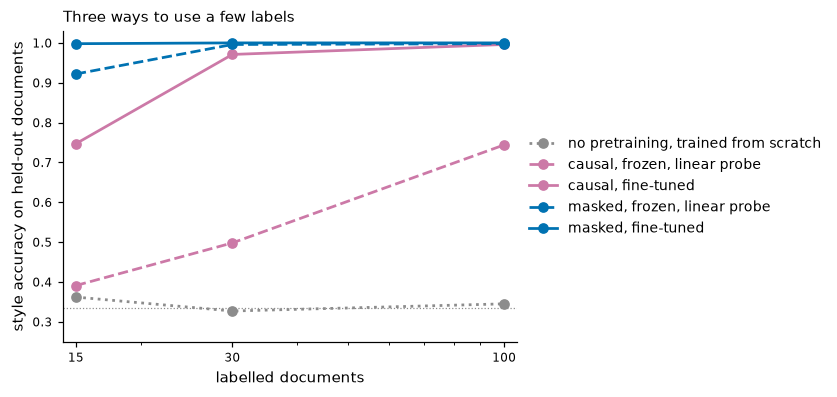

In [8]:
Xte, yte = probe_docs["tokens"][3000:], probe_docs["style"][3000:]
rows = {}
for n in (15, 30, 100):
    idx = np.random.default_rng(0).permutation(3000)[:n]
    Xn, yn = probe_docs["tokens"][idx], probe_docs["style"][idx]
    set_seed(0)
    scratch = O.fine_tune(O.Classifier(T.Transformer(causal=False, **BASE)), Xn, yn, lr_encoder=2e-3)
    rows[("no pretraining", "trained from scratch")] = rows.get(("no pretraining", "trained from scratch"), []) + [O.accuracy(scratch, Xte, yte)]
    for name in ["causal", "masked"]:
        f = models[name].features
        frozen = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(f(Xn), yn).score(f(Xte), yte)
        tuned = O.fine_tune(O.Classifier(copy.deepcopy(models[name])), Xn, yn)
        rows[(name, "frozen, linear probe")] = rows.get((name, "frozen, linear probe"), []) + [frozen]
        rows[(name, "fine-tuned")] = rows.get((name, "fine-tuned"), []) + [O.accuracy(tuned, Xte, yte)]
ft = pd.DataFrame(rows, index=pd.Index([15, 30, 100], name="labelled documents")).T
display(ft.round(3))
fig, ax = plt.subplots(figsize=(7.5, 3.5))
style_of = {"frozen, linear probe": "--", "fine-tuned": "-", "trained from scratch": ":"}
for (name, how), vals in ft.iterrows():
    ax.plot([15, 30, 100], vals, "o", ls=style_of[how], color={"causal": viz.PINK, "masked": viz.BLUE, "no pretraining": viz.GREY}[name], label=f"{name}, {how}")
ax.axhline(1 / 3, color=viz.GREY, ls=":", lw=0.8)
ax.set_xscale("log"); ax.set_xticks([15, 30, 100]); ax.set_xticklabels([15, 30, 100]); ax.tick_params(axis="x", which="minor", labelbottom=False)
ax.set_ylim(0.25, 1.03); ax.set_xlabel("labelled documents"); ax.set_ylabel("style accuracy on held-out documents")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5)); ax.set_title("Three ways to use a few labels")
plt.show()

**Reading the result.**

* *Without pretraining there is nothing to work with.* The same architecture trained from scratch on 15, 30 or 100
  labelled documents stays at chance (0.33 to 0.36).
* *Fine-tuning closes most of the gap between the objectives.* The causal model goes from 0.39, 0.50 and 0.74 as a
  frozen feature extractor to 0.75, 0.97 and 1.00 when fine-tuned. The masked model was already at 0.92 and above
  frozen and reaches 1.00. With 30 labels or more, a fine-tuned causal model is as good as a masked one.
* So the causal model *knows* the style. What it lacks is a form of that knowledge that survives averaging its states
  and reading them linearly. Three hundred steps of fine-tuning are enough to rearrange it.

This changes how to read section 2. "Which objective gives the best frozen features" and "which objective gives the
best starting point for fine-tuning" are different questions, and the second has a much less dramatic answer.

## 5. What each model can do: fill in a blank, write a document

Representations are one use of a pretrained model. The other is to use it directly.

**Filling in a blank.** We hide the same 15% of tokens in the test documents for both models. The masked model reads
both sides of each blank. The causal model can only use what comes before it. The comparison is split by the kind of
token that was hidden; the interesting row is the *bound value*, the `8` in `set D 8`, which nothing before it
predicts but which a later `ask D 8` gives away.

,masked model (reads both sides),causal model (reads the left side only),hidden tokens
all hidden tokens,0.371,0.276,18839
filler word,0.272,0.260,13105
bound key,0.494,0.132,812
bound value,0.431,0.127,812
queried key,0.493,0.609,1090
recalled value,0.612,0.819,1053


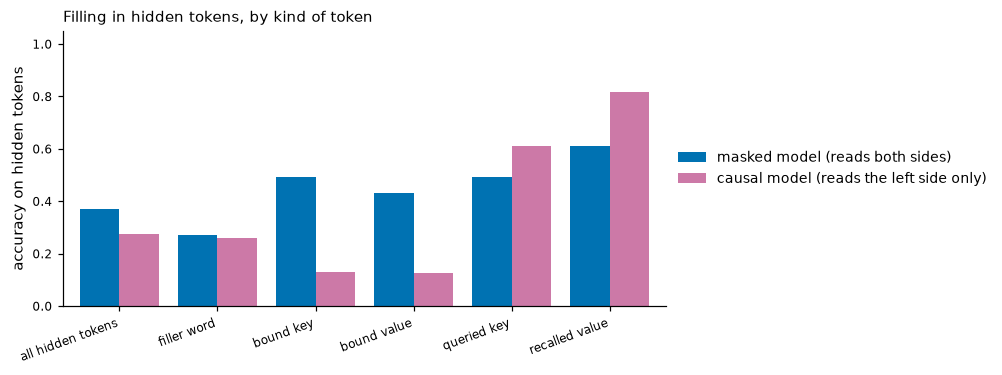

In [9]:
fill_masked = O.cloze_table(O.cloze(models["masked"], test["tokens"], HIDDEN), test["tokens"], HIDDEN, test["kind"])
fill_causal = O.cloze_table(models["causal"].logprobs(test["tokens"]), test["tokens"], HIDDEN, test["kind"])
fill = pd.DataFrame({"masked model (reads both sides)": fill_masked["accuracy"], "causal model (reads the left side only)": fill_causal["accuracy"],
                     "hidden tokens": fill_masked["tokens"].astype(int)})
display(fill.round(3))
fig, ax = plt.subplots(figsize=(9, 3.3))
x = np.arange(len(fill))
ax.bar(x - 0.2, fill.iloc[:, 0], 0.4, color=viz.BLUE, label=fill.columns[0]); ax.bar(x + 0.2, fill.iloc[:, 1], 0.4, color=viz.PINK, label=fill.columns[1])
ax.set_xticks(x); ax.set_xticklabels(fill.index, rotation=20, ha="right"); ax.set_ylabel("accuracy on hidden tokens"); ax.set_ylim(0, 1.05)
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5)); ax.set_title("Filling in hidden tokens, by kind of token")
plt.show()

**Writing a document.** A causal model generates by construction: sample a token, append it, repeat. A masked model
has no such procedure built in, but one can be improvised: start from a document made entirely of `<mask>`, let the
model predict every position, keep the predictions it is most confident about, and repeat with the rest still hidden.
(This is the idea behind the masked image generators of notebook 10.)

To judge generated documents we check four things that are true of real ones:

* **grammar**: `set` and `ask` are followed by a key and then a value, and keys and values appear nowhere else;
* **asks bound**: a queried key was bound earlier;
* **recall**: the value after `ask K` is the one bound to `K`;
* **word order**: the share of word-to-word steps that follow the document's style (about 0.8 in real documents,
  0.22 for random tokens).

,grammar,asks bound,recall,word order
real documents,1.000,1.000,1.000,0.798
"causal model, left to right",0.990,0.991,0.730,0.780
"masked model, 1 round",0.000,0.000,0.000,0.179
"masked model, 4 rounds",0.166,0.067,0.000,0.398
"masked model, 16 rounds",0.645,0.405,0.824,0.731
"masked model, 63 rounds",0.994,0.646,0.806,0.844
"masked model, 63 rounds, left to right",0.860,0.413,0.548,0.648
random tokens,0.002,0.000,0.000,0.219


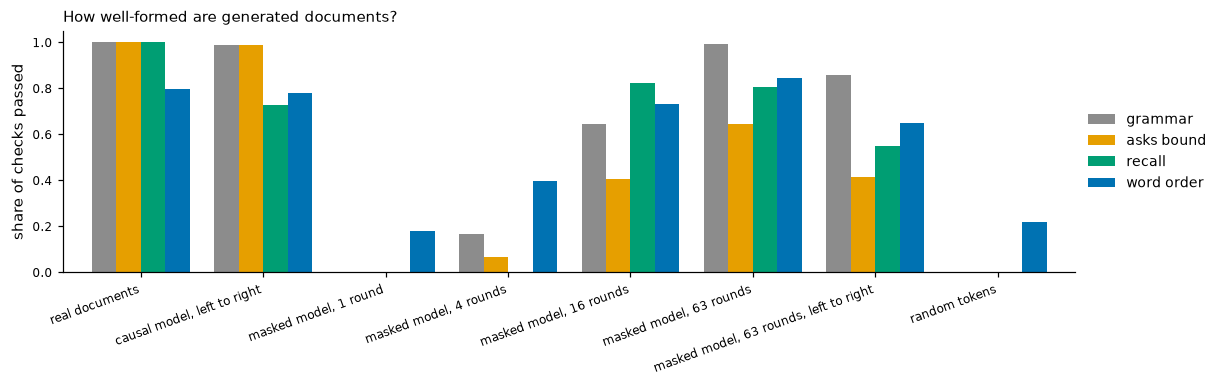

saved figures/nb04_two_ways_to_generate.gif  (17 frames, 101 kB)


'figures/nb04_two_ways_to_generate.gif'

In [10]:
N_GEN = 300
checks = {"real documents": O.document_checks(test["tokens"][:N_GEN]),
          "causal model, left to right": O.document_checks(O.sample_causal(models["causal"], N_GEN))}
for rounds in (1, 4, 16, 63):
    checks[f"masked model, {rounds} round{'s' if rounds > 1 else ''}"] = O.document_checks(O.sample_masked(models["masked"], N_GEN, steps=rounds))
checks["masked model, 63 rounds, left to right"] = O.document_checks(O.sample_masked(models["masked"], N_GEN, steps=63, order="left-to-right"))
checks["random tokens"] = O.document_checks(np.random.default_rng(0).integers(W.SET, W.VOCAB, (N_GEN, W.DOC_LEN)))
checks = pd.DataFrame(checks).T.astype(float)
display(checks.round(3))
fig, ax = plt.subplots(figsize=(11, 3.4))
x = np.arange(len(checks)); cols = [viz.GREY, viz.ORANGE, viz.GREEN, viz.BLUE]
for k, c in enumerate(checks.columns):
    ax.bar(x + (k - 1.5) * 0.2, checks[c], 0.2, color=cols[k], label=c)
ax.set_xticks(x); ax.set_xticklabels(checks.index, rotation=20, ha="right"); ax.set_ylim(0, 1.05); ax.set_ylabel("share of checks passed")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5)); ax.set_title("How well-formed are generated documents?")
plt.show()

L = 32
causal_doc = O.sample_causal(models["causal"], 4, length=L, seed=3)[0]
_, masked_hist = O.sample_masked(models["masked"], 4, length=L, steps=16, seed=3, record=True)
fig, axes = plt.subplots(2, 1, figsize=(13, 3.6))
def frame(f):
    for ax in axes:
        ax.clear()
    k = int(np.ceil((L - 1) * f / 16)) + 1
    words = [W.WORDS[t] if i < k else "" for i, t in enumerate(causal_doc)]
    viz.token_strip(axes[0], words, colors=[viz.PINK if i == k - 1 and f else "#F2F2F2" if i < k else "#FFFFFF" for i in range(L)], wrap=16, fontsize=7, edge=["#CCCCCC"] * L)
    axes[0].set_title(f"causal model: {k} of {L} tokens written, always the next one", fontsize=9, loc="left")
    now, before = masked_hist[min(f, len(masked_hist) - 1)][0], masked_hist[max(min(f, len(masked_hist) - 1) - 1, 0)][0]
    words = [W.WORDS[t] if t != W.MASK else "" for t in now]
    viz.token_strip(axes[1], words, colors=["#FFFFFF" if t == W.MASK else viz.SKY if b == W.MASK else "#F2F2F2" for t, b in zip(now, before)], wrap=16, fontsize=7, edge=["#CCCCCC"] * L)
    axes[1].set_title(f"masked model: round {f} of 16, filling the positions it is surest about", fontsize=9, loc="left")
viz.save_gif(fig, frame, range(17), "nb04_two_ways_to_generate.gif", fps=2)

![A causal model writes a document from left to right; a masked model starts from an all-hidden document and fills positions in order of confidence](figures/nb04_two_ways_to_generate.gif)

### Try it: how many rounds does the masked model need?

Static preview at the default settings {'rounds': 16, 'order': 'confidence'}. Run the notebook to get the controls.


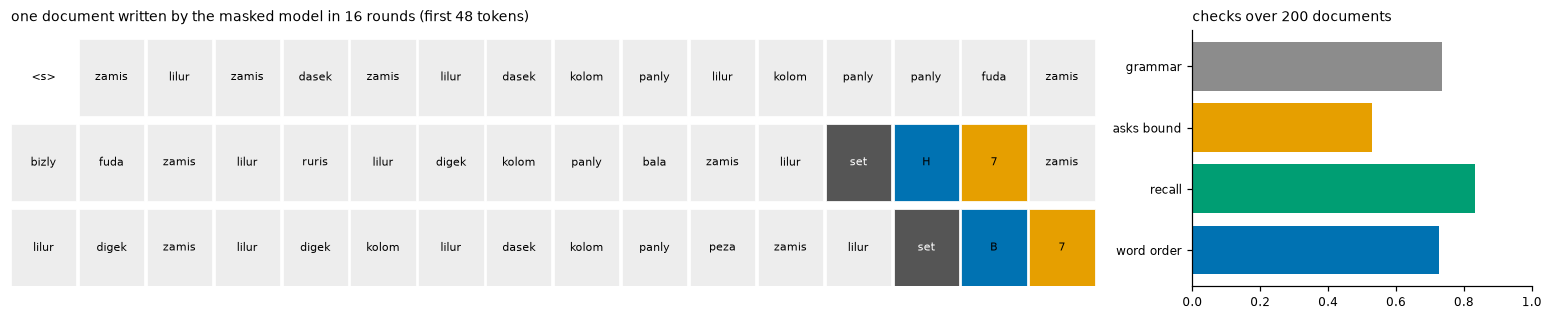

In [11]:
def rounds_explorer(rounds=16, order="confidence"):
    docs = O.sample_masked(models["masked"], 200, steps=rounds, order=order, seed=1)
    c = O.document_checks(docs)
    fig, axes = plt.subplots(1, 2, figsize=(14, 2.8), gridspec_kw=dict(width_ratios=[3.2, 1]))
    viz.token_strip(axes[0], [W.WORDS[t] for t in docs[0][:48]], colors=viz.doc_colors(docs[0][:48]), wrap=16, fontsize=7)
    axes[0].set_title(f"one document written by the masked model in {rounds} round{'s' if rounds > 1 else ''} (first 48 tokens)", fontsize=9, loc="left")
    axes[1].barh(list(c), list(c.values()), color=[viz.GREY, viz.ORANGE, viz.GREEN, viz.BLUE]); axes[1].set_xlim(0, 1); axes[1].invert_yaxis()
    axes[1].set_title("checks over 200 documents", fontsize=9)
    plt.show()
viz.explore(rounds_explorer, rounds=[16, 1, 2, 4, 8, 32, 63], order=["confidence", "left-to-right"])

**Reading the results.**

*Filling in.* Overall the masked model fills 37% of the blanks correctly and the causal model 28%. The difference is
where it should be. For a hidden **bound key** or **bound value**, nothing to the left helps, and the causal model
is at chance (0.13, with eight keys and eight values). The masked model reads ahead to a later `ask` and gets 0.49
and 0.43. For ordinary words the right-hand neighbour adds a little (0.272 against 0.260). For **queried keys** and
**recalled values** the causal model is *better* (0.61 and 0.82 against 0.49 and 0.61): these are predictable from
the left, and a model trained on every position has learned the lookup more thoroughly than one trained on 15% of
them.

*Writing.* The causal model's documents are close to real ones: grammar 0.99, queries of bound keys 0.99, word order
0.78 (real documents: 0.80). Its recall of the right value, 0.73, is the weak point, as in notebook 03.

The masked model's documents depend entirely on the number of rounds. Filling everything in one round gives
nothing usable (grammar 0.00, word order below that of random tokens), because every position is predicted without
knowing what the others will be: each choice is plausible alone and the combination is not. With 16 rounds grammar
reaches 0.65. With one token per round, 63 rounds, grammar is 0.99 and word order 0.84, but a third of its queries
ask for keys that were never bound (0.65). Filling in order of confidence is better than filling from left to right
on every check.

So a masked model can be made to generate, at the same cost as a causal one (one pass per token), and the result is
locally well-formed and globally less consistent. Whether fewer, parallel rounds can match one-token-at-a-time
generation is the question that masked and diffusion generators answer for images in notebooks 07 to 10.

## 6. Design choices of masked pretraining

BERT made several choices that later work revisited. Each is described below and then measured. To keep the runtime
down, these runs are 2,000 steps long and are compared with the two baseline runs of section 2 **at step 2,000**. The
two baseline seeds tell us how large a difference has to be before it means anything.

**How much to hide.** BERT hid 15%. Hide too little and each document yields few predictions to learn from; hide too
much and too little context is left to predict from. [Wettig et al., 2022](https://arxiv.org/abs/2202.08005) found that 40% works as well or better for large
models, and that even 80% retains most of the quality.

**The same blanks every time, or new ones.** BERT chose the hidden positions once, when the data was prepared
(*static* masking). RoBERTa ([Liu et al., 2019](https://arxiv.org/abs/1907.11692)) draws new positions every time a document is seen (*dynamic* masking), so
the model never sees the same puzzle twice.

**Tokens or spans.** SpanBERT ([Joshi et al., 2019](https://arxiv.org/abs/1907.10529)) hides contiguous runs of tokens. A single hidden token can often be
guessed from its immediate neighbours; a hidden span forces the model to use context from further away.

**How the encoder knows where tokens are.** BERT learned one vector per position; T5 uses a learned bias for each
relative offset, which is what every model in this notebook uses. Notebook 03 recommended RoPE for causal models.
We test RoPE in the encoder, and an encoder with no position information at all.

In [12]:
for rate in (0.05, 0.40, 0.75):
    pretrain(f"masked, {rate:.0%} hidden", "masked", steps=2000, rate=rate)
pretrain("masked, static blanks", "masked", steps=2000, static=True)
pretrain("masked, spans hidden", "masked", steps=2000, span=True)
pretrain("masked, RoPE positions", "masked", steps=2000, arch=dict(BASE, pos="rope"))
pretrain("masked, no positions", "masked", steps=2000, arch=dict(BASE, pos="none"))

masked, 5% hidden                      style probe with 15 / 100 labels: 0.48 / 0.88   topic: 0.99   (81s)
masked, 40% hidden                     style probe with 15 / 100 labels: 0.93 / 1.00   topic: 1.00   (82s)
masked, 75% hidden                     style probe with 15 / 100 labels: 0.46 / 0.82   topic: 0.99   (88s)
masked, static blanks                  style probe with 15 / 100 labels: 0.72 / 0.97   topic: 1.00   (84s)
masked, spans hidden                   style probe with 15 / 100 labels: 0.48 / 0.90   topic: 1.00   (87s)
masked, RoPE positions                 style probe with 15 / 100 labels: 0.37 / 0.65   topic: 1.00   (96s)
masked, no positions                   style probe with 15 / 100 labels: 0.35 / 0.36   topic: 0.99   (80s)


,"style, 15 labels","style, 100 labels","topic, 15 labels","fill-in accuracy, words"
"baseline (15%, dynamic, single tokens, relative bias)",0.891,0.999,0.999,0.266
"baseline, second seed",0.622,0.944,0.992,0.265
"masked, 5% hidden",0.480,0.880,0.994,0.247
"masked, 40% hidden",0.934,0.997,1.000,0.273
"masked, 75% hidden",0.463,0.822,0.993,0.243
"masked, static blanks",0.715,0.967,0.996,0.263
"masked, spans hidden",0.484,0.897,0.999,0.263
"masked, RoPE positions",0.375,0.654,0.997,0.225
"masked, no positions",0.355,0.357,0.994,0.039


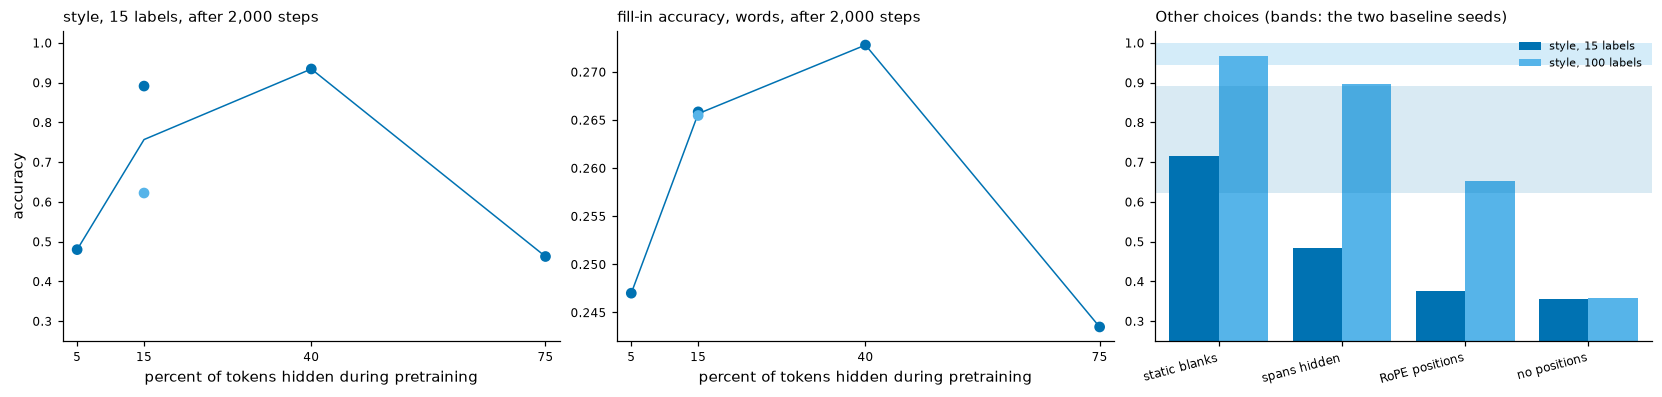

In [13]:
ABL = ["masked, 5% hidden", "masked, 40% hidden", "masked, 75% hidden", "masked, static blanks", "masked, spans hidden",
       "masked, RoPE positions", "masked, no positions"]
at2000 = pd.DataFrame({"baseline (15%, dynamic, single tokens, relative bias)": hist["masked"].loc[2000], "baseline, second seed": hist["masked, second seed"].loc[2000],
                       **{name: hist[name].loc[2000] for name in ABL}}).T
display(at2000.round(3))
lo, hi = at2000.iloc[:2].min(), at2000.iloc[:2].max()                 # the spread between the two baseline seeds

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
rates = [5, 15, 15, 40, 75]; names = ["masked, 5% hidden", "masked", "masked, second seed", "masked, 40% hidden", "masked, 75% hidden"]
for ax, col in zip(axes[:2], [S15, FILL]):
    vals = [hist[n].loc[2000, col] for n in names]
    ax.plot([5, 15, 40, 75], [vals[0], np.mean(vals[1:3]), vals[3], vals[4]], "-", color=viz.BLUE, lw=1)
    ax.scatter(rates, vals, color=[viz.BLUE, viz.BLUE, viz.SKY, viz.BLUE, viz.BLUE], zorder=3)
    ax.set_xlabel("percent of tokens hidden during pretraining"); ax.set_xticks([5, 15, 40, 75]); ax.set_title(col + ", after 2,000 steps")
axes[0].set_ylim(0.25, 1.03); axes[0].set_ylabel("accuracy")
others = ["masked, static blanks", "masked, spans hidden", "masked, RoPE positions", "masked, no positions"]
x = np.arange(len(others))
axes[2].bar(x - 0.2, at2000.loc[others, S15], 0.4, color=viz.BLUE, label=S15); axes[2].bar(x + 0.2, at2000.loc[others, S100], 0.4, color=viz.SKY, label=S100)
axes[2].axhspan(lo[S15], hi[S15], color=viz.BLUE, alpha=0.15, lw=0); axes[2].axhspan(lo[S100], hi[S100], color=viz.SKY, alpha=0.25, lw=0)
axes[2].set_xticks(x); axes[2].set_xticklabels([o.replace("masked, ", "") for o in others], rotation=15, ha="right"); axes[2].set_ylim(0.25, 1.03)
axes[2].set_title("Other choices (bands: the two baseline seeds)"); axes[2].legend(fontsize=7, loc="upper right")
plt.show()

### Try it: pick a masking rate

The left panel shows what a document looks like to the model at that rate. The right panel shows how the style probe
developed during pretraining at that rate (coloured), against the other rates (grey).

Static preview at the default settings {'percent_hidden': 15, 'document': 3}. Run the notebook to get the controls.


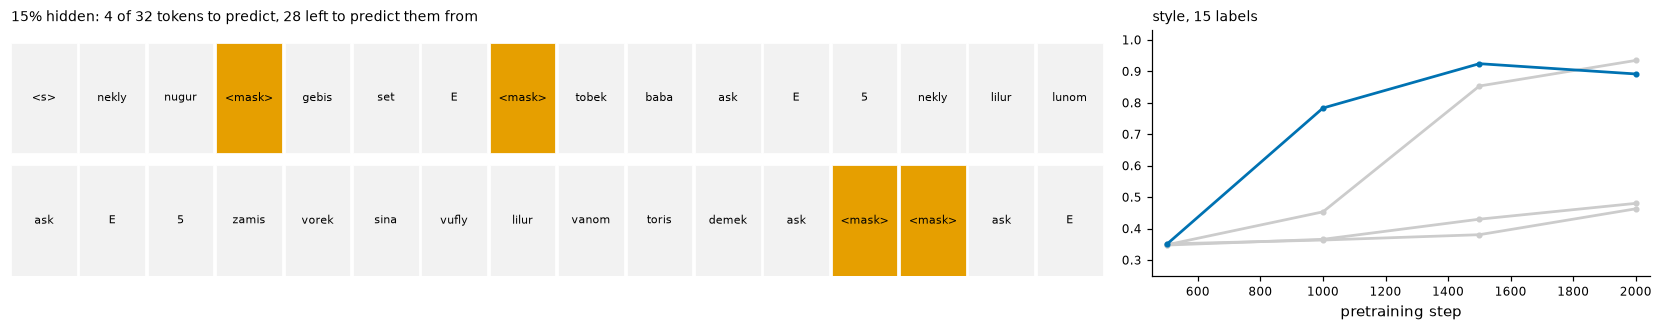

In [14]:
RATE_RUN = {5: "masked, 5% hidden", 15: "masked", 40: "masked, 40% hidden", 75: "masked, 75% hidden"}
def rate_explorer(percent_hidden=15, document=3):
    fig, axes = plt.subplots(1, 2, figsize=(15, 2.9), gridspec_kw=dict(width_ratios=[2.2, 1]))
    doc = test["tokens"][document][:32][None]
    x, hidden = O.corrupt(doc, percent_hidden / 100, np.random.default_rng(2))
    viz.token_strip(axes[0], [W.WORDS[t] for t in x[0]], colors=[viz.ORANGE if x[0, i] == W.MASK else viz.PINK if hidden[0, i] and x[0, i] != doc[0, i] else viz.SKY if hidden[0, i] else PLAIN for i in range(32)], wrap=16, fontsize=7)
    axes[0].set_title(f"{percent_hidden}% hidden: {int(hidden.sum())} of 32 tokens to predict, {32 - int(hidden.sum())} left to predict them from", fontsize=9, loc="left")
    for r, name in RATE_RUN.items():
        h = hist[name][S15].loc[:2000]
        axes[1].plot(h.index, h, "o-", ms=3, color=viz.BLUE if r == percent_hidden else "#CCCCCC", zorder=3 if r == percent_hidden else 1)
    axes[1].set_ylim(0.25, 1.03); axes[1].set_xlabel("pretraining step"); axes[1].set_title(S15, fontsize=9)
    plt.show()
viz.explore(rate_explorer, percent_hidden=[15, 5, 40, 75], document=(0, 50, 1, 3))

**Reading the result.** The two baseline runs differ by 0.27 on the 15-label style probe (0.89 and 0.62 at step
2,000) and by 0.001 on fill-in accuracy (0.266 and 0.265). Fill-in accuracy is therefore the steadier measure, and a
difference on the style probe counts only if it falls outside the range of the two seeds.

* *How much to hide.* Both measures give the same shape: best at 40%, worse at 15%, clearly worse at 5% and at 75%.
  Fill-in accuracy is 0.247, 0.266, 0.273 and 0.243. With 5% hidden there are too few predictions to learn from; with
  75% hidden there is too little left to predict from. This agrees with [Wettig et al., 2022](https://arxiv.org/abs/2202.08005) that 15% is not the optimum.
  They found 80% still usable for large models; for this small one, 75% is not.
* *Static or dynamic.* No difference that we can detect: static masking is inside the range of the two baseline
  seeds on both style probes (0.72 and 0.97) and 0.003 lower on fill-in accuracy (0.263). In 2,000 steps each document is seen about six times, so there is
  little repetition for dynamic masking to remove. RoBERTa's gain from it was small as well, over far longer
  training.
* *Spans.* Fill-in accuracy is 0.263, again 0.003 below the baseline, and the style probe is lower than both baseline seeds (0.48 with
  15 labels, 0.90 with 100). In this corpus style lives in the order of *adjacent* words, and hiding runs of tokens
  removes exactly the adjacent evidence. SpanBERT's gains are on tasks about spans, such as question answering,
  which this corpus does not have. Here span masking did not help.
* *Positions.* With **no positions** the encoder cannot learn word order at all: fill-in accuracy on words is 0.04
  and style is at chance. In notebook 03 a causal model with no positions still worked, because the causal mask
  leaks position. An encoder has no mask, so nothing leaks: without a position scheme it is a bag of words. With
  **RoPE** the encoder is well behind at 2,000 steps (0.38 and 0.65 on style, 0.225 on fill-in). In development runs
  outside this notebook it did get there, after between 2,500 and more than 6,000 steps depending on the seed. We
  do not know why RoPE is slow in this small encoder, and would not generalise from it.

## 7. Design choices: what changed since BERT

| Choice | Original | What the field moved to | Why | Measured here |
|---|---|---|---|---|
| Fraction hidden | 15% ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)) | up to 40% for large models ([Wettig et al., 2022](https://arxiv.org/abs/2202.08005)) | More predictions per document, as long as enough context remains | Best at 40%; 5% and 75% clearly worse (fill-in accuracy 0.247, 0.266, 0.273, 0.243) |
| Which positions | fixed when the data is prepared | redrawn every time (RoBERTa, [Liu et al., 2019](https://arxiv.org/abs/1907.11692)) | The model never sees the same puzzle twice | No difference beyond seed-to-seed variation at 2,000 steps |
| What is hidden | single tokens | whole words, spans (SpanBERT, [Joshi et al., 2019](https://arxiv.org/abs/1907.10529)) | Removes the easy guesses from immediate neighbours | Fill-in about the same; style probe lower (0.48 against 0.62 to 0.89 with 15 labels) |
| What replaces a hidden token | `<mask>` 80%, random 10%, unchanged 10% | unchanged in BERT's successors; removed entirely in ELECTRA | Keeps pretraining inputs close to downstream inputs | not ablated |
| Second objective | next-sentence prediction | dropped (RoBERTa, [Liu et al., 2019](https://arxiv.org/abs/1907.11692)) | It did not help once the masked objective was trained longer | not ablated: our documents have no sentence pairs |
| Training signal | the hidden 15% of positions | every position: replaced-token detection (ELECTRA, [Clark et al., 2020](https://arxiv.org/abs/2003.10555)) | More learning per step | Challenge Problem 1: style probe 1.00 with 15 labels, but the topic probe falls to chance |
| Positions in an encoder | learned absolute vectors | relative bias (T5, [Raffel et al., 2019](https://arxiv.org/abs/1910.10683)); later RoPE ([Su et al., 2021](https://arxiv.org/abs/2104.09864)) | Offsets generalise better than addresses | No positions fails outright; RoPE much slower than a relative bias in this encoder (section 6) |
| Architecture | encoder only | encoder-decoder (T5, BART), then decoder only (GPT-3, [Brown et al., 2020](https://arxiv.org/abs/2005.14165)) | One model that can both read and write; see below | Encoder: best frozen features. Decoder: well-formed documents, and equal to the encoder once fine-tuned (sections 2 to 5) |

**Why decoders became the default.** An encoder gives the best representations for classification, but it needs a
task-specific head and labelled data for every new task, and it cannot write. An encoder-decoder can write, at the
cost of two stacks. [Brown et al., 2020](https://arxiv.org/abs/2005.14165) showed that a large enough causal model needs neither a head nor fine-tuning for
many tasks: the task is described in the prompt and the answer is generated. A single objective, a single stack and
no per-task training turned out to matter more than the better representations of bidirectional models. Encoders
remain the standard choice where the output is a label or an embedding, such as search and classification.

**Where each choice appears in well-known models** (from the cited papers):

| Model | Architecture | Objective | Corruption |
|---|---|---|---|
| BERT ([Devlin et al., 2018](https://arxiv.org/abs/1810.04805)) | encoder | masked tokens + next-sentence prediction | 15%, static, 80/10/10 |
| RoBERTa ([Liu et al., 2019](https://arxiv.org/abs/1907.11692)) | encoder | masked tokens | 15%, dynamic |
| SpanBERT ([Joshi et al., 2019](https://arxiv.org/abs/1907.10529)) | encoder | masked spans + span-boundary objective | 15%, contiguous spans |
| ELECTRA ([Clark et al., 2020](https://arxiv.org/abs/2003.10555)) | encoder (+ small generator) | replaced-token detection | 15% replaced by generator samples |
| T5 ([Raffel et al., 2019](https://arxiv.org/abs/1910.10683)) | encoder-decoder | span corruption | 15%, spans of mean length 3, one marker per span |
| BART ([Lewis et al., 2019](https://arxiv.org/abs/1910.13461)) | encoder-decoder | reconstruct the whole document | text infilling and sentence shuffling |
| GPT-3 ([Brown et al., 2020](https://arxiv.org/abs/2005.14165)) | decoder | next token | none |

## 8. Scorecard

In [15]:
rows = []
causal_res = W.evaluate_lm(models["causal"].logprobs)
rows.append(W.scorecard_row("causal transformer (relative bias), 3,000 steps", causal_res, recall_natural=W.natural_recall(models["causal"].logprobs).correct.mean()))
for name, label in [("masked", "masked transformer (15%), 3,000 steps"), ("span corruption", "encoder-decoder, span corruption, 3,000 steps")]:
    rows.append(dict(model=label, family="language"))
for row, name in zip(rows, ["causal", "masked", "span corruption"]):
    f = models[name].features
    row.update(probe_style=W.probe(f, 100, "style"), probe_topic=W.probe(f, 100, "topic"), probe_style_15=hist[name].iloc[-1][S15],
               params=sum(p.numel() for p in models[name].parameters()), train_seconds=secs[name])
metrics.append_rows(rows, "04_objectives")
card = metrics.load_scorecard()
show = [c for c in ["notebook", "model", "gap", "recall_natural", "probe_style", "probe_style_15", "probe_topic", "params", "train_seconds"] if c in card.columns]
display(card[card.notebook.isin(["03_transformer", "04_objectives"])][show].round(3))

,notebook,model,gap,recall_natural,probe_style,probe_style_15,probe_topic,params,train_seconds
12,03_transformer,"transformer, 2017 block",0.159,0.137,0.992,NaN,NaN,109905.0,40.227
13,03_transformer,"transformer, pre-norm + RMSNorm",0.085,0.633,0.928,NaN,NaN,109713.0,44.623
14,03_transformer,"transformer, + RoPE",0.058,0.639,0.749,NaN,NaN,109713.0,47.953
15,03_transformer,"transformer, modern block (RoPE, RMSNorm, SwiGLU)",0.059,0.642,0.991,NaN,NaN,108817.0,49.842
16,03_transformer,"transformer, modern + 1 key/value head",0.062,0.636,0.997,NaN,NaN,96529.0,47.895
17,03_transformer,"transformer, modern + MoE (4 experts, top-1)",0.065,0.635,0.982,NaN,NaN,305169.0,99.390
18,03_transformer,"transformer, modern block, 13,500 steps",0.046,0.975,0.971,NaN,NaN,108817.0,476.455
19,04_objectives,"causal transformer (relative bias), 3,000 steps",0.039,0.833,0.744,0.399,0.999,109081.0,127.365
20,04_objectives,"masked transformer (15%), 3,000 steps",NaN,NaN,0.998,0.892,0.997,109337.0,122.349
21,04_objectives,"encoder-decoder, span corruption, 3,000 steps",NaN,NaN,0.942,0.594,0.999,182726.0,174.642


## Challenge Problem 1: A training signal from every position: ELECTRA

A masked model learns only from the positions that were hidden. ELECTRA replaces the hidden tokens with samples from a small masked model and
trains the main model to say, for every position, whether the token is original or replaced. Pretrain it with
`pretrain("replaced-token detection", "replaced-token detection", rate=0.15)` and compare its three probes, step by step, with the masked baseline.
Then explain what you see in the topic probe. Hint: check whether the generator's replacements fit the document's topic, using `W.E_TOPIC[topic, class, word]`,
the probability of each word within its class under each topic.

In [16]:
# Start your code here

### Challenge Problem 1 Solution

replaced-token detection               style probe with 15 / 100 labels: 1.00 / 1.00   topic: 0.25   (168s)


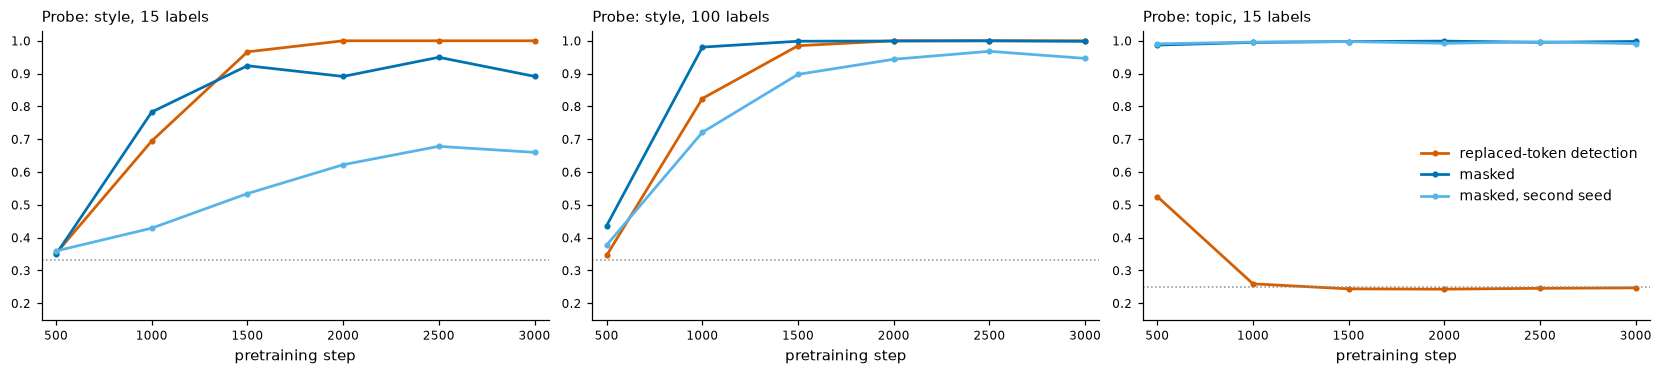

,"style, 15 labels","style, 100 labels","topic, 15 labels"
replaced-token detection,1.000,1.000,0.247
masked,0.892,0.998,0.998
"masked, second seed",0.660,0.946,0.991


style probe with 15 labels, every 500 steps:


step,500,1000,1500,2000,2500,3000
replaced-token detection,0.35,0.69,0.97,1.00,1.00,1.00
masked,0.35,0.78,0.92,0.89,0.95,0.89
"masked, second seed",0.36,0.43,0.53,0.62,0.68,0.66


average probability of the word under the document's topic:  original words 0.221   generator's replacements 0.208   random words 0.101


In [17]:
pretrain("replaced-token detection", "replaced-token detection", rate=0.15)
E = ["replaced-token detection", "masked", "masked, second seed"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))
for ax, col, chance in zip(axes, [S15, S100, T15], [1 / 3, 1 / 3, 1 / 4]):
    for name, c in zip(E, [viz.VERMILION, viz.BLUE, viz.SKY]):
        ax.plot(hist[name].index, hist[name][col], "o-", ms=3, color=c, label=name)
    ax.axhline(chance, color=viz.GREY, ls=":", lw=1); ax.set_ylim(0.15, 1.03); ax.set_xlabel("pretraining step"); ax.set_title("Probe: " + col)
axes[2].legend(loc="center right"); plt.show()
display(pd.DataFrame({name: hist[name].iloc[-1][[S15, S100, T15]] for name in E}).T.round(3))
print("style probe with 15 labels, every 500 steps:"); display(pd.DataFrame({name: hist[name][S15] for name in E}).T.round(2))

# Do the generator's replacements fit the topic of the document they are put into?
el = models["replaced-token detection"]; docs, topic = probe_docs["tokens"][:1000], probe_docs["topic"][:1000]
masked, hidden = O.corrupt(docs, 0.15, np.random.default_rng(0), rule="mask")
hidden &= W.WORD_CLASS[docs] >= 0                                    # look at ordinary words only
with torch.no_grad():
    p = torch.softmax(el.generator.token_logits(torch.as_tensor(masked))[..., :W.VOCAB], -1)[torch.as_tensor(hidden)]
samples = torch.multinomial(p, 1, generator=torch.Generator().manual_seed(0))[:, 0].numpy()
r, c = np.where(hidden)
def topic_fit(tokens):
    ok = W.WORD_CLASS[tokens] >= 0
    return float(W.E_TOPIC[topic[r][ok], W.WORD_CLASS[tokens[ok]], (tokens[ok] - W.FILL0) % W.N_WORD].mean())
random_words = np.random.default_rng(1).integers(W.FILL0, W.VOCAB, len(r))
print(f"average probability of the word under the document's topic:  original words {topic_fit(docs[r, c]):.3f}   "
      f"generator's replacements {topic_fit(samples):.3f}   random words {topic_fit(random_words):.3f}")
# Read the figure and the table. Replaced-token detection ends with a perfect style probe: 1.00 with 15 labels,
# against 0.89 and 0.66 for the two masked runs. It was not faster than the better masked run over the first 1,000
# steps. Its topic probe falls to 0.25, which is chance.
# Why topic is lost: the check shows that the generator's replacements fit the document's topic almost as well as the
# original words do (0.208 against 0.221; random words 0.101). A replacement that fits the topic cannot be caught by
# knowing the topic, so the discriminator gains nothing from representing it. What gives a replacement away is word
# order, and that is what it learns. A representation contains what its objective rewards; nothing guarantees the
# rest. This is a property of our small setting, where topic is easy for the generator; the paper reports strong
# results across standard benchmarks.

## Challenge Problem 2: Which layer holds the features?

The probes above use the states after the last layer. Use `model.residuals(tokens)` (the embedding output and the output of each layer) to probe
the causal and the masked model at each depth: mean-pool each one over the document and measure the style probe (15 and 100 labels) and the topic
probe (15 labels) with `O.probe_curve`. Where does each kind of information first become available, and why?

In [18]:
# Start your code here

### Challenge Problem 2 Solution

In [19]:
out = {}
for name in ["causal", "masked"]:
    res = models[name].residuals(probe_docs["tokens"])
    for depth, r in zip(["token vectors", "after layer 1", "after layer 2"], res):
        feats = r.mean(1); s, t = O.probe_curve(feats, "style", (15, 100)), O.probe_curve(feats, "topic", (15,))
        out[(name, depth)] = {S15: s[15], S100: s[100], T15: t[15]}
display(pd.DataFrame(out).T.round(3))
# Read the table. Topic can be read from the averaged token vectors alone (0.93 to 0.97): it is a matter of which
# words occur. Style cannot (chance): it is a matter of order, and order enters only when attention combines
# neighbouring tokens, which first happens in layer 1.
# The second layer improves the masked model's few-label probe (0.74 to 0.88 with 15 labels) and does not improve the
# causal model's (0.44 to 0.42). That is consistent with the causal model's last layer being shaped for predicting
# the next token, not for summarising the document, and it is one reason features are often taken from a middle
# layer of a causal model.

style, 15 labels  style, 100 labels  topic, 15 labels
causal token vectors             0.359              0.377             0.973
       after layer 1             0.435              0.839             0.991
       after layer 2             0.420              0.795             0.998
masked token vectors             0.353              0.371             0.927
       after layer 1             0.736              0.988             0.984
       after layer 2             0.883              0.998             0.998

## Final summary

* Causal, masked and span-corruption pretraining are the same idea, hide something and predict it, with different
  things hidden and different positions readable. The architecture follows from that: decoder, encoder,
  encoder-decoder.
* **No objective won everything.** The masked encoder gave the best frozen features and filled blanks that need the
  right-hand context. The causal decoder wrote well-formed documents and was better on everything predictable from
  the left. Replaced-token detection gave a perfect style probe and lost topic entirely.
* **A representation contains what its objective rewards.** Topic was learned by every objective that predicts
  words and discarded by the one objective that did not need it.
* **Frozen features and fine-tuning answer different questions.** The causal model's frozen features were far
  behind, and after fine-tuning on 30 labels it matched the masked model.
* Of BERT's design choices, the **masking rate** mattered here (40% best, 5% and 75% clearly worse), **dynamic
  masking** made no detectable difference, and **span masking** did not help on a corpus whose structure is local.
  An encoder with **no position information** is a bag of words.
* Two runs of the same model differed by more than most of the design choices. Several results in this notebook
  could only be stated because the baseline was run twice.
* What is still missing: every model so far has used our 81-token vocabulary and one small size. Notebook 05 turns to
  what it takes to make pretraining scale: tokenisers, the optimiser recipe, and how quality depends on model size
  and data.

## References

* Jacob Devlin, Ming-Wei Chang, Kenton Lee et al. (2018). **BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding**. arXiv:1810.04805. [arxiv.org/abs/1810.04805](https://arxiv.org/abs/1810.04805)
* Yinhan Liu, Myle Ott, Naman Goyal et al. (2019). **RoBERTa: A Robustly Optimized BERT Pretraining Approach**. arXiv:1907.11692. [arxiv.org/abs/1907.11692](https://arxiv.org/abs/1907.11692)
* Mandar Joshi, Danqi Chen, Yinhan Liu et al. (2019). **SpanBERT: Improving Pre-training by Representing and Predicting Spans**. arXiv:1907.10529. [arxiv.org/abs/1907.10529](https://arxiv.org/abs/1907.10529)
* Kevin Clark, Minh-Thang Luong, Quoc V. Le et al. (2020). **ELECTRA: Pre-training Text Encoders as Discriminators Rather Than Generators**. arXiv:2003.10555. [arxiv.org/abs/2003.10555](https://arxiv.org/abs/2003.10555)
* Alexander Wettig, Tianyu Gao, Zexuan Zhong et al. (2022). **Should You Mask 15% in Masked Language Modeling?**. arXiv:2202.08005. [arxiv.org/abs/2202.08005](https://arxiv.org/abs/2202.08005)
* Colin Raffel, Noam Shazeer, Adam Roberts et al. (2019). **Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer**. arXiv:1910.10683. [arxiv.org/abs/1910.10683](https://arxiv.org/abs/1910.10683)
* Mike Lewis, Yinhan Liu, Naman Goyal et al. (2019). **BART: Denoising Sequence-to-Sequence Pre-training for Natural Language Generation, Translation, and Comprehension**. arXiv:1910.13461. [arxiv.org/abs/1910.13461](https://arxiv.org/abs/1910.13461)
* Tom B. Brown, Benjamin Mann, Nick Ryder et al. (2020). **Language Models are Few-Shot Learners**. arXiv:2005.14165. [arxiv.org/abs/2005.14165](https://arxiv.org/abs/2005.14165)
* Peter Shaw, Jakob Uszkoreit, Ashish Vaswani (2018). **Self-Attention with Relative Position Representations**. arXiv:1803.02155. [arxiv.org/abs/1803.02155](https://arxiv.org/abs/1803.02155)
* Jianlin Su, Yu Lu, Shengfeng Pan et al. (2021). **RoFormer: Enhanced Transformer with Rotary Position Embedding**. arXiv:2104.09864. [arxiv.org/abs/2104.09864](https://arxiv.org/abs/2104.09864)
* Matthew E. Peters, Mark Neumann, Mohit Iyyer et al. (2018). **Deep contextualized word representations**. arXiv:1802.05365. [arxiv.org/abs/1802.05365](https://arxiv.org/abs/1802.05365)
* Jeremy Howard, Sebastian Ruder (2018). **Universal Language Model Fine-tuning for Text Classification**. arXiv:1801.06146. [arxiv.org/abs/1801.06146](https://arxiv.org/abs/1801.06146)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).